# SmartHome Energy IQ: Predictive Analytics on Household Energy Consumption

Five syllabus-aligned techniques applied to the Smart Home Energy Consumption dataset (same pipeline as the RetailIQ reference notebook):
1. Multiple Linear Regression: daily energy consumption prediction
2. Logistic Regression: high-consumption classification
3. Decision Tree Classifier: high-consumption classification
4. Support Vector Machine (SVM): high-consumption classification
5. **K-Nearest Neighbours (KNN)**: high-consumption classification (replaces K-Means from the reference)

Update `DATA_FILE` in the first code cell if needed, then run all cells from top to bottom.

## 1. Load libraries and dataset

In [1]:
# If needed, run in a notebook cell: %pip install pandas numpy matplotlib seaborn scikit-learn
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, log_loss, roc_curve
)

# Change this path to where you saved the dataset (the CSV, or the downloaded .zip that contains it)
DATA_FILE = "smart_home_energy_consumption_large.csv"
if not os.path.exists(DATA_FILE):
    for alt in ["archive__2_.zip", "archive.zip"]:
        if os.path.exists(alt):
            DATA_FILE = alt
            break
if not os.path.exists(DATA_FILE):
    raise FileNotFoundError("Update DATA_FILE with the correct path to smart_home_energy_consumption_large.csv (or the zip)")

df = pd.read_csv(DATA_FILE)   # pandas reads a single-file .zip directly
print("Original shape:", df.shape)
print(df.columns.tolist())
display(df.head())

Original shape: (100000, 8)
['Home ID', 'Appliance Type', 'Energy Consumption (kWh)', 'Time', 'Date', 'Outdoor Temperature (°C)', 'Season', 'Household Size']


,Home ID,Appliance Type,Energy Consumption (kWh),Time,Date,Outdoor Temperature (°C),Season,Household Size
0,94,Fridge,0.20,21:12,2023-12-02,-1.0,Fall,2
1,435,Oven,0.23,20:11,2023-08-06,31.1,Summer,5
2,466,Dishwasher,0.32,06:39,2023-11-21,21.3,Fall,3
3,496,Heater,3.92,21:56,2023-01-21,-4.2,Winter,1
4,137,Microwave,0.44,04:31,2023-08-26,34.5,Summer,5


## 2. Data preprocessing

In [2]:
# Combine date and time, convert types, and remove rows with missing essential values.
ENERGY = "Energy Consumption (kWh)"
TEMP = "Outdoor Temperature (°C)"
df["DateTime"] = pd.to_datetime(df["Date"].astype(str) + " " + df["Time"].astype(str), errors="coerce")
df = df.dropna(subset=["Home ID", "Appliance Type", ENERGY, "DateTime",
                       TEMP, "Season", "Household Size"])
df[ENERGY] = pd.to_numeric(df[ENERGY], errors="coerce")
df[TEMP] = pd.to_numeric(df[TEMP], errors="coerce")
df = df.dropna(subset=[ENERGY, TEMP])

# Remove invalid energy values and duplicates.
df = df[df[ENERGY] > 0]
df = df.drop_duplicates().copy()

# Time-based features.
df["Hour"] = df["DateTime"].dt.hour
df["DayOfWeek"] = df["DateTime"].dt.dayofweek
df["Month"] = df["DateTime"].dt.month
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)
df = df.sort_values("DateTime").reset_index(drop=True)

print("Cleaned shape:", df.shape)
print("Unique homes:", df["Home ID"].nunique())
print("Unique appliance types:", df["Appliance Type"].nunique())
print("Date range:", df["DateTime"].min(), "to", df["DateTime"].max())
print("Missing values:\n", df.isnull().sum())
print()
display(df.describe().round(2))

Cleaned shape: (100000, 13)
Unique homes: 500
Unique appliance types: 10
Date range: 2023-01-01 00:07:00 to 2024-01-01 23:53:00
Missing values:
 Home ID                     0
Appliance Type              0
Energy Consumption (kWh)    0
Time                        0
Date                        0
Outdoor Temperature (°C)    0
Season                      0
Household Size              0
DateTime                    0
Hour                        0
DayOfWeek                   0
Month                       0
IsWeekend                   0
dtype: int64



,Home ID,Energy Consumption (kWh),Outdoor Temperature (°C),Household Size,DateTime,Hour,DayOfWeek,Month,IsWeekend
count,100000.00,100000.00,100000.00,100000.00,100000,100000.00,100000.00,100000.00,100000.00
mean,250.37,1.50,14.95,3.00,2023-07-02 12:17:39.069600,11.49,3.01,6.49,0.29
min,1.00,0.10,-10.00,1.00,2023-01-01 00:07:00,0.00,0.00,1.00,0.00
25%,125.00,0.59,2.40,2.00,2023-04-02 10:04:45,5.00,1.00,4.00,0.00
50%,250.00,1.23,14.90,3.00,2023-07-01 23:35:00,11.00,3.00,6.00,0.00
75%,375.00,1.87,27.40,4.00,2023-10-02 03:56:00,18.00,5.00,10.00,1.00
max,500.00,5.00,40.00,5.00,2024-01-01 23:53:00,23.00,6.00,12.00,1.00
std,144.44,1.18,14.44,1.42,NaN,6.93,2.01,3.45,0.45


## 3. Exploratory data analysis

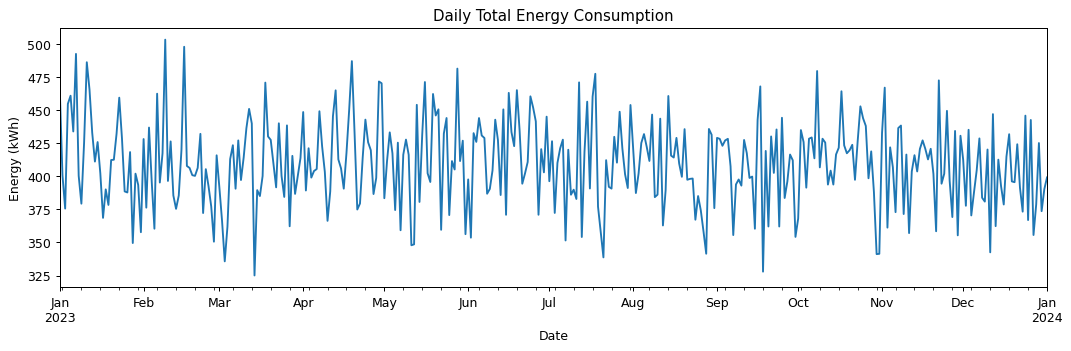

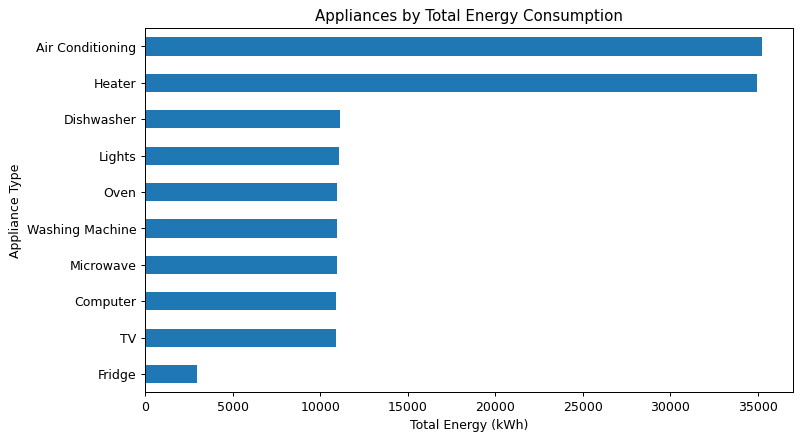

In [3]:
# Daily energy consumption over time
daily_energy = df.set_index("DateTime")[ENERGY].resample("D").sum()
daily_energy.plot(figsize=(12, 4), title="Daily Total Energy Consumption")
plt.xlabel("Date"); plt.ylabel("Energy (kWh)"); plt.tight_layout(); plt.show()

# Top appliances by total energy
top_appliances = df.groupby("Appliance Type")[ENERGY].sum().nlargest(10)
top_appliances.sort_values().plot(kind="barh", figsize=(9, 5), title="Appliances by Total Energy Consumption")
plt.xlabel("Total Energy (kWh)"); plt.tight_layout(); plt.show()

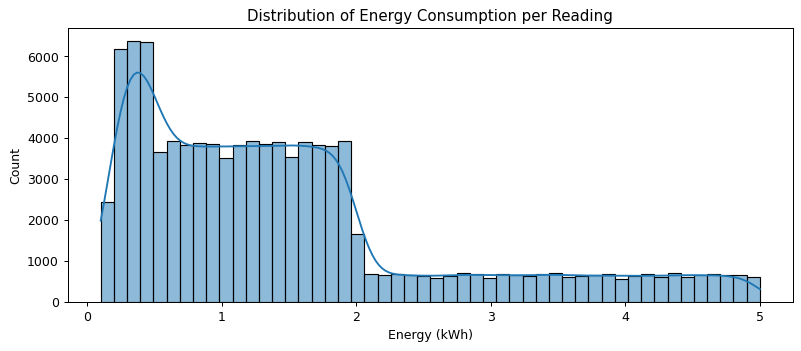

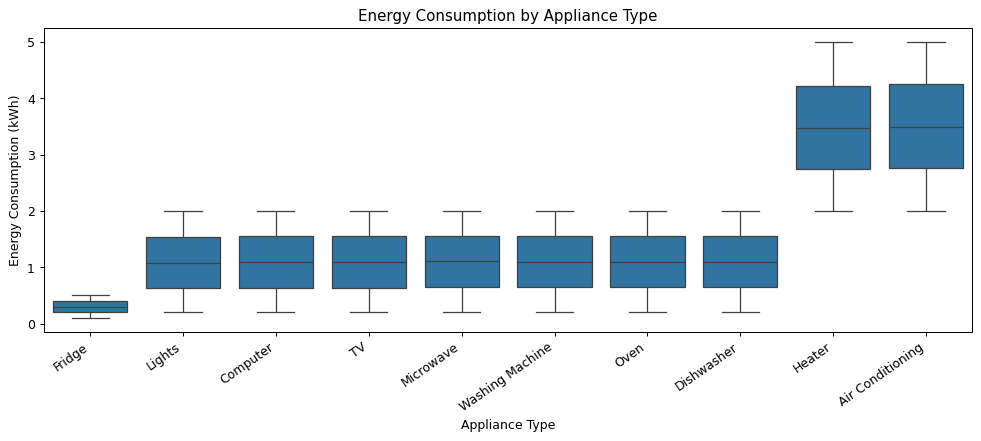

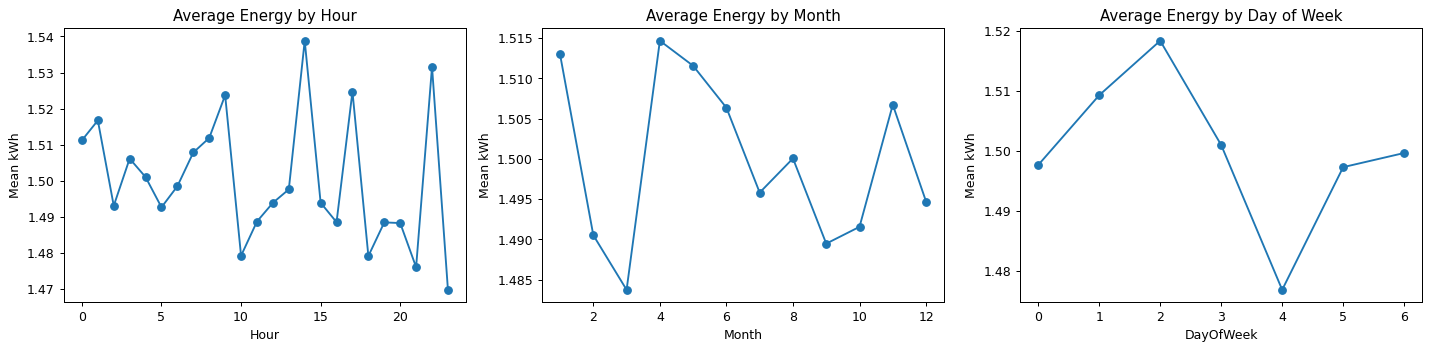

In [4]:
# Distribution of energy per reading
plt.figure(figsize=(9, 4))
sns.histplot(df[ENERGY], bins=50, kde=True)
plt.title("Distribution of Energy Consumption per Reading"); plt.xlabel("Energy (kWh)")
plt.tight_layout(); plt.show()

# Energy by appliance type (boxplot)
order = df.groupby("Appliance Type")[ENERGY].mean().sort_values().index
plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x="Appliance Type", y=ENERGY, order=order)
plt.xticks(rotation=35, ha="right"); plt.title("Energy Consumption by Appliance Type")
plt.tight_layout(); plt.show()

# Average energy by hour, month, and day of week
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("Hour")[ENERGY].mean().plot(ax=axes[0], marker="o", title="Average Energy by Hour")
df.groupby("Month")[ENERGY].mean().plot(ax=axes[1], marker="o", title="Average Energy by Month")
df.groupby("DayOfWeek")[ENERGY].mean().plot(ax=axes[2], marker="o", title="Average Energy by Day of Week")
for ax in axes: ax.set_ylabel("Mean kWh")
plt.tight_layout(); plt.show()

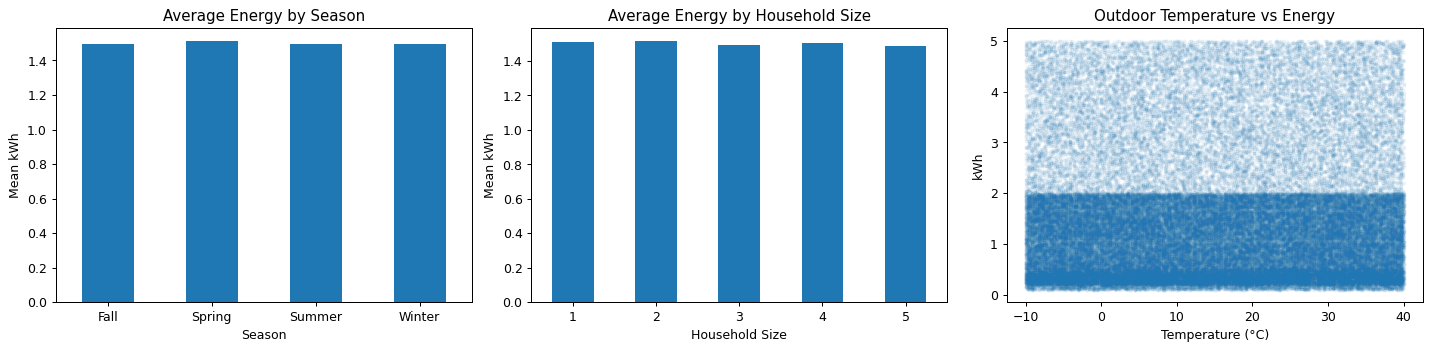

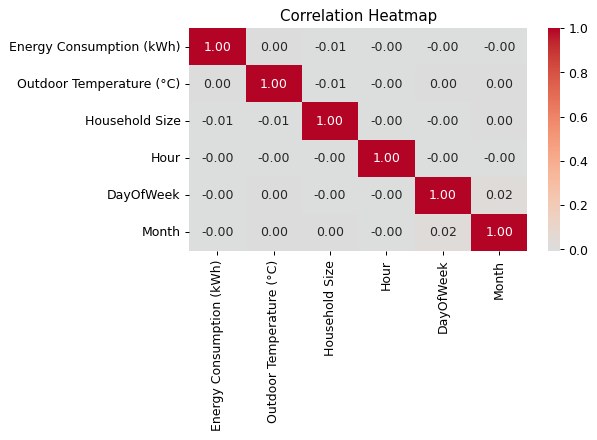

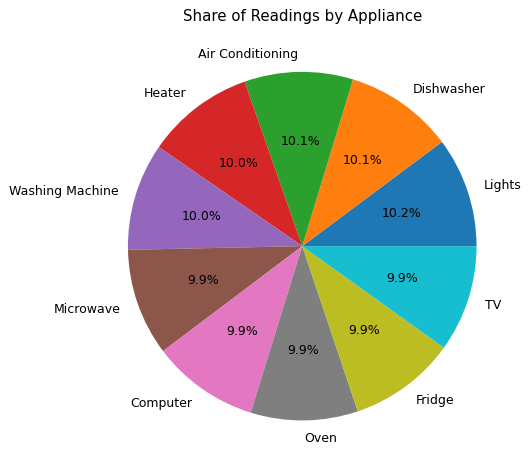

In [5]:
# Season, household size, and outdoor temperature
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("Season")[ENERGY].mean().plot(kind="bar", ax=axes[0], title="Average Energy by Season", rot=0)
df.groupby("Household Size")[ENERGY].mean().plot(kind="bar", ax=axes[1], title="Average Energy by Household Size", rot=0)
axes[2].scatter(df[TEMP], df[ENERGY], alpha=0.05, s=5)
axes[2].set_title("Outdoor Temperature vs Energy"); axes[2].set_xlabel("Temperature (°C)"); axes[2].set_ylabel("kWh")
for ax in axes[:2]: ax.set_ylabel("Mean kWh")
plt.tight_layout(); plt.show()

# Correlation heatmap of numeric columns
plt.figure(figsize=(7, 5))
sns.heatmap(df[[ENERGY, TEMP, "Household Size", "Hour", "DayOfWeek", "Month"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

# Appliance share of readings
df["Appliance Type"].value_counts().plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6), title="Share of Readings by Appliance")
plt.ylabel(""); plt.tight_layout(); plt.show()

**EDA takeaways**
- Energy per reading depends mainly on the **appliance type**: Air Conditioning and Heater use roughly 2-5 kWh, Fridge is the lowest (0.1-0.5 kWh), and the remaining appliances use 0.2-2 kWh.
- Outdoor temperature, household size, hour, month, and day of week show almost no correlation with energy in this dataset (the data appears synthetic/randomly generated).
- The `Season` column is not an astronomical season (for example, December is labelled "Fall" and January to March "Winter"), so `Month` is used as the calendar feature.

## 4. Multiple Linear Regression: daily energy consumption prediction

MAE: 26.71
MSE: 1036.81
RMSE: 32.2
R-squared: -0.0934

Coefficients:


,Coefficient
Lag1,0.0608
Lag2,-0.0325
Lag7,-0.0003
DayOfWeek,-0.2170
Month,0.1196
DayOfMonth,-0.0701


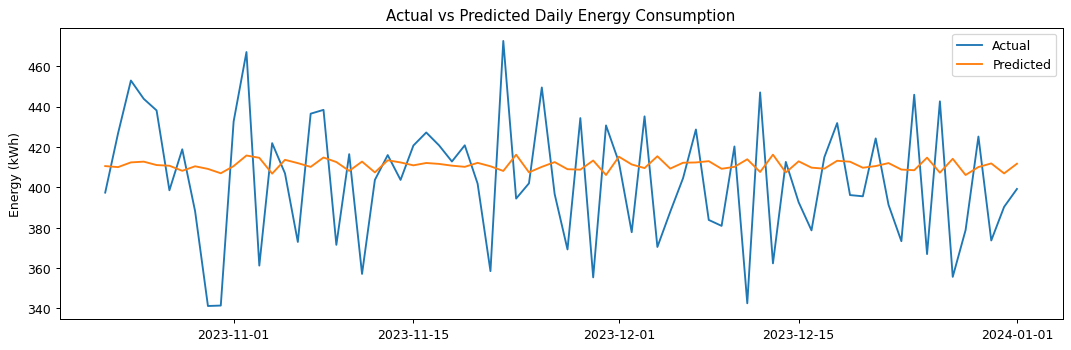

In [6]:
# Use past daily energy and calendar values to predict daily energy consumption.
daily = df.set_index("DateTime")[ENERGY].resample("D").sum().to_frame("Energy")
daily["Lag1"] = daily["Energy"].shift(1)
daily["Lag2"] = daily["Energy"].shift(2)
daily["Lag7"] = daily["Energy"].shift(7)
daily["DayOfWeek"] = daily.index.dayofweek
daily["Month"] = daily.index.month
daily["DayOfMonth"] = daily.index.day
daily = daily.dropna()

features_reg = ["Lag1", "Lag2", "Lag7", "DayOfWeek", "Month", "DayOfMonth"]
X_reg, y_reg = daily[features_reg], daily["Energy"]
cut = int(len(daily) * 0.8)
X_train_reg, X_test_reg = X_reg.iloc[:cut], X_reg.iloc[cut:]
y_train_reg, y_test_reg = y_reg.iloc[:cut], y_reg.iloc[cut:]

reg_model = LinearRegression()
reg_model.fit(X_train_reg, y_train_reg)
pred_reg = reg_model.predict(X_test_reg)

print("MAE:", round(mean_absolute_error(y_test_reg, pred_reg), 2))
print("MSE:", round(mean_squared_error(y_test_reg, pred_reg), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, pred_reg)), 2))
print("R-squared:", round(r2_score(y_test_reg, pred_reg), 4))

print("\nCoefficients:")
display(pd.Series(reg_model.coef_, index=features_reg).round(4).to_frame("Coefficient"))

plt.figure(figsize=(12, 4))
plt.plot(y_test_reg.index, y_test_reg, label="Actual")
plt.plot(y_test_reg.index, pred_reg, label="Predicted")
plt.title("Actual vs Predicted Daily Energy Consumption"); plt.ylabel("Energy (kWh)")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretation:** R-squared is close to zero or slightly negative, meaning the model does no better than predicting the average day. Daily totals in this dataset are essentially random noise around ~410 kWh (autocorrelation is near zero), so past days and calendar values carry almost no predictive information. This is a property of the data, not a coding error.

## 5. Create the classification target and features

The reference notebook predicts customer churn. This dataset has no customers, so the equivalent classification task is predicting **High Consumption**: a reading is labelled `1` if its energy use is above the dataset's mean consumption, otherwise `0`. As in the reference (earlier snapshot for training, later snapshot for testing), the data is split **by time**: the first 80% of readings train the models and the last 20% test them.

High-consumption threshold: 1.500 kWh
Train rows: 80000 | Test rows: 20000
Train period: 2023-01-01 to 2023-10-19
Test period : 2023-10-19 to 2024-01-01
Training class distribution:
 HighConsumption
0    48319
1    31681
Name: count, dtype: int64


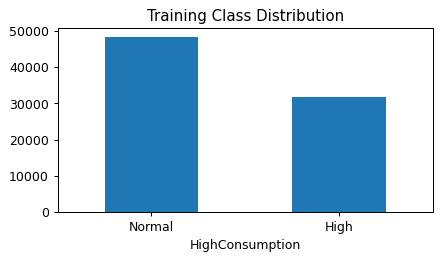

In [7]:
threshold = df[ENERGY].mean()
df["HighConsumption"] = (df[ENERGY] > threshold).astype(int)
print(f"High-consumption threshold: {threshold:.3f} kWh")

# One-hot encode appliance type; keep numeric features.
feature_df = pd.get_dummies(
    df[["Appliance Type", TEMP, "Household Size", "Hour", "DayOfWeek", "Month"]],
    columns=["Appliance Type"], dtype=int
)
feature_cols = feature_df.columns.tolist()

split = int(len(df) * 0.8)   # time-ordered split (df is sorted by DateTime)
X_train, y_train = feature_df.iloc[:split], df["HighConsumption"].iloc[:split]
X_test, y_test = feature_df.iloc[split:], df["HighConsumption"].iloc[split:]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train period:", df["DateTime"].iloc[0].date(), "to", df["DateTime"].iloc[split - 1].date())
print("Test period :", df["DateTime"].iloc[split].date(), "to", df["DateTime"].iloc[-1].date())
print("Training class distribution:\n", y_train.value_counts())

y_train.value_counts().sort_index().rename({0: "Normal", 1: "High"}).plot(
    kind="bar", rot=0, title="Training Class Distribution", figsize=(5, 3))
plt.tight_layout(); plt.show()

## 6. Classification evaluation helper

In [8]:
def evaluate_classifier(name, model):
    predictions = model.predict(X_test)
    print("\n" + name)
    print("Accuracy :", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(y_test, predictions, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_test, predictions, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_test, predictions, zero_division=0), 4))
    print(classification_report(y_test, predictions, zero_division=0))
    matrix = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(4, 3)); plt.imshow(matrix)
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.xticks([0, 1], ["Normal", "High"]); plt.yticks([0, 1], ["Normal", "High"])
    for (i, j), value in np.ndenumerate(matrix):
        plt.text(j, i, str(value), ha="center", va="center", color="red")
    plt.tight_layout(); plt.show()
    if hasattr(model, "predict_proba") and len(np.unique(y_test)) == 2:
        probabilities = model.predict_proba(X_test)
        print("ROC-AUC:", round(roc_auc_score(y_test, probabilities[:, 1]), 4))
        print("Log loss:", round(log_loss(y_test, probabilities), 4))

## 7. Logistic Regression


Logistic Regression
Accuracy : 0.8046
Precision: 1.0
Recall   : 0.5086
F1-score : 0.6742
              precision    recall  f1-score   support

           0       0.76      1.00      0.86     12050
           1       1.00      0.51      0.67      7950

    accuracy                           0.80     20000
   macro avg       0.88      0.75      0.77     20000
weighted avg       0.85      0.80      0.79     20000

ROC-AUC: 0.7933
Log loss: 0.4267


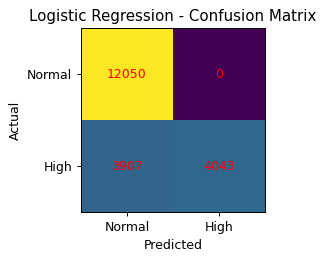

In [9]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])
logistic_model.fit(X_train, y_train)
evaluate_classifier("Logistic Regression", logistic_model)

## 8. Decision Tree Classifier


Decision Tree
Accuracy : 0.8046
Precision: 1.0
Recall   : 0.5086
F1-score : 0.6742
              precision    recall  f1-score   support

           0       0.76      1.00      0.86     12050
           1       1.00      0.51      0.67      7950

    accuracy                           0.80     20000
   macro avg       0.88      0.75      0.77     20000
weighted avg       0.85      0.80      0.79     20000

ROC-AUC: 0.7953
Log loss: 0.4266


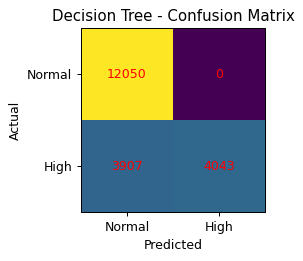

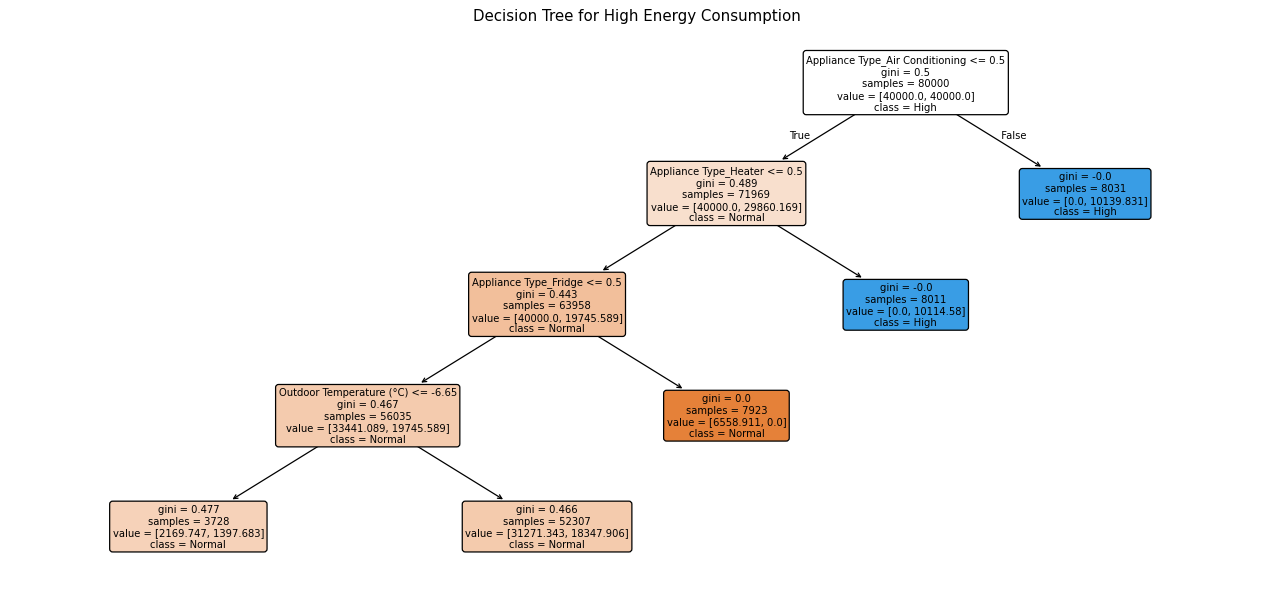

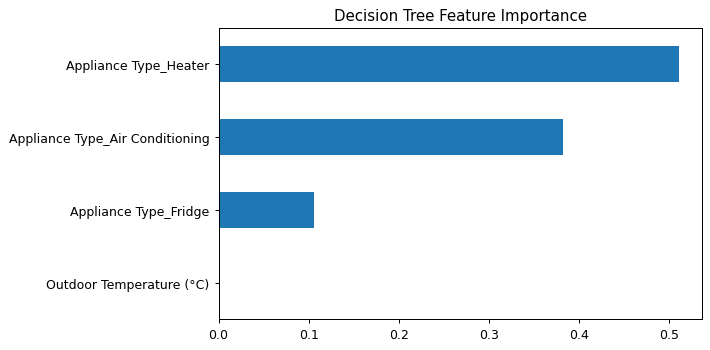

In [10]:
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10,
                                     class_weight="balanced", random_state=42))
])
tree_model.fit(X_train, y_train)
evaluate_classifier("Decision Tree", tree_model)

plt.figure(figsize=(18, 8))
plot_tree(tree_model.named_steps["model"], feature_names=feature_cols,
          class_names=["Normal", "High"], filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree for High Energy Consumption"); plt.show()

importances = pd.Series(tree_model.named_steps["model"].feature_importances_, index=feature_cols)
importances[importances > 0].sort_values().plot(kind="barh", figsize=(8, 4), title="Decision Tree Feature Importance")
plt.tight_layout(); plt.show()

## 9. Support Vector Machine (SVM)


Support Vector Machine (SVM)
Accuracy : 0.8046
Precision: 1.0
Recall   : 0.5086
F1-score : 0.6742
              precision    recall  f1-score   support

           0       0.76      1.00      0.86     12050
           1       1.00      0.51      0.67      7950

    accuracy                           0.80     20000
   macro avg       0.88      0.75      0.77     20000
weighted avg       0.85      0.80      0.79     20000

ROC-AUC: 0.7786
Log loss: 0.4429


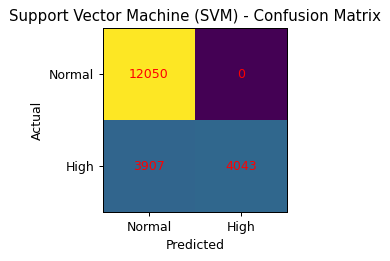

In [11]:
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1.0, probability=True,
                  class_weight="balanced", random_state=42))
])
# SVM training time grows roughly with the square of the number of rows, so the SVM is trained on a
# random sample of 10,000 training rows (seeded for reproducibility). It is still tested on the full test set.
svm_idx = X_train.sample(n=min(10000, len(X_train)), random_state=42).index
svm_model.fit(X_train.loc[svm_idx], y_train.loc[svm_idx])
evaluate_classifier("Support Vector Machine (SVM)", svm_model)

## 10. K-Nearest Neighbours (KNN)

This section replaces K-Means from the reference notebook. KNN classifies a reading by the majority class among its *k* closest training readings, so features must be scaled. As the reference chose *k* for K-Means with the elbow and silhouette plots, here *k* is chosen on a **validation set** (the last 20% of the training period), never on the test set.

Selected k: 49


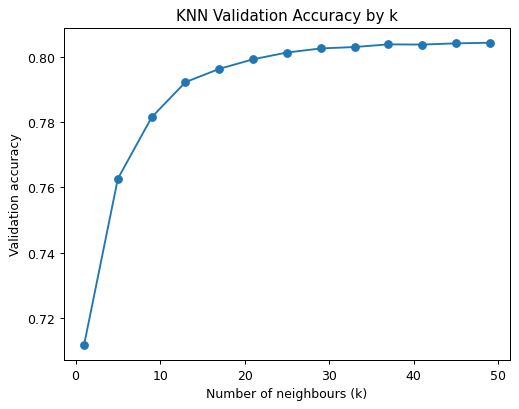

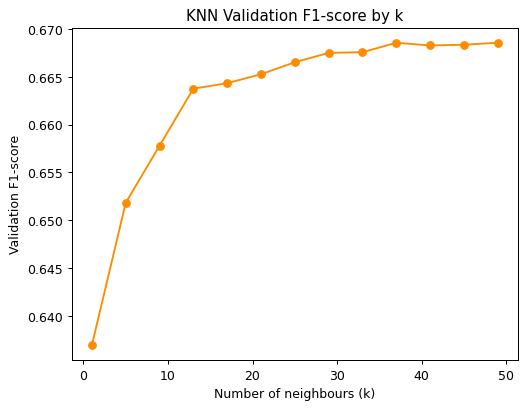

In [12]:
# Choose k using a time-ordered validation split inside the training period.
val_cut = int(len(X_train) * 0.8)
X_fit, X_val = X_train.iloc[:val_cut], X_train.iloc[val_cut:]
y_fit, y_val = y_train.iloc[:val_cut], y_train.iloc[val_cut:]

k_values = list(range(1, 52, 4))   # 1, 5, 9, ..., 49
val_acc, val_f1 = [], []
for k in k_values:
    knn_try = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])
    knn_try.fit(X_fit, y_fit)
    p = knn_try.predict(X_val)
    val_acc.append(accuracy_score(y_val, p))
    val_f1.append(f1_score(y_val, p, zero_division=0))

plt.plot(k_values, val_acc, marker="o")
plt.title("KNN Validation Accuracy by k"); plt.xlabel("Number of neighbours (k)")
plt.ylabel("Validation accuracy"); plt.show()

plt.plot(k_values, val_f1, marker="o", color="darkorange")
plt.title("KNN Validation F1-score by k"); plt.xlabel("Number of neighbours (k)")
plt.ylabel("Validation F1-score"); plt.show()

best_k = k_values[int(np.argmax(val_f1))]
print("Selected k:", best_k)


K-Nearest Neighbours (KNN)
Accuracy : 0.8043
Precision: 0.998
Recall   : 0.5087
F1-score : 0.6739
              precision    recall  f1-score   support

           0       0.76      1.00      0.86     12050
           1       1.00      0.51      0.67      7950

    accuracy                           0.80     20000
   macro avg       0.88      0.75      0.77     20000
weighted avg       0.85      0.80      0.79     20000

ROC-AUC: 0.7954
Log loss: 0.4212


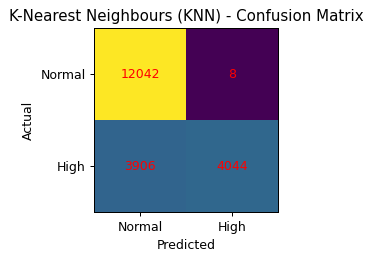

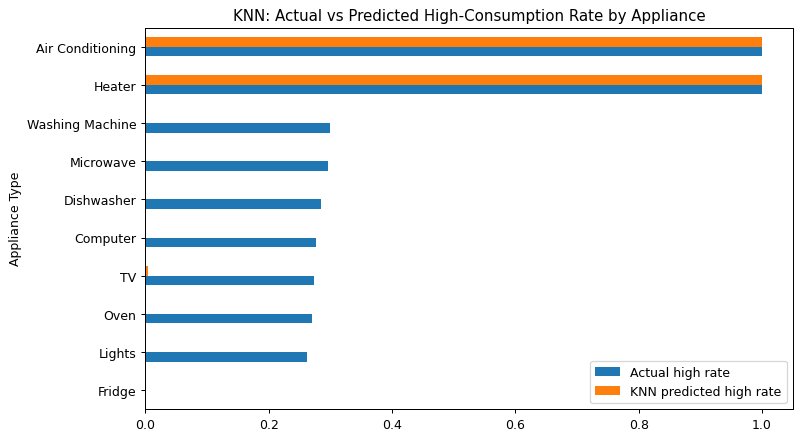

In [13]:
knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=best_k))
])
knn_model.fit(X_train, y_train)
evaluate_classifier("K-Nearest Neighbours (KNN)", knn_model)

# Predicted high-consumption rate vs actual rate for each appliance (test period)
test_view = df.iloc[split:].copy()
test_view["KNN_Pred"] = knn_model.predict(X_test)
rates = test_view.groupby("Appliance Type")[["HighConsumption", "KNN_Pred"]].mean()
rates.columns = ["Actual high rate", "KNN predicted high rate"]
rates.sort_values("Actual high rate").plot(kind="barh", figsize=(9, 5),
                                           title="KNN: Actual vs Predicted High-Consumption Rate by Appliance")
plt.tight_layout(); plt.show()

## 11. Compare classification models

Regression (Multiple Linear Regression) - daily energy:
  R-squared: -0.0934 | RMSE: 32.2 kWh


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8046,1.000,0.5086,0.6742,0.7933
Decision Tree,0.8046,1.000,0.5086,0.6742,0.7953
SVM,0.8046,1.000,0.5086,0.6742,0.7786
KNN,0.8043,0.998,0.5087,0.6739,0.7954


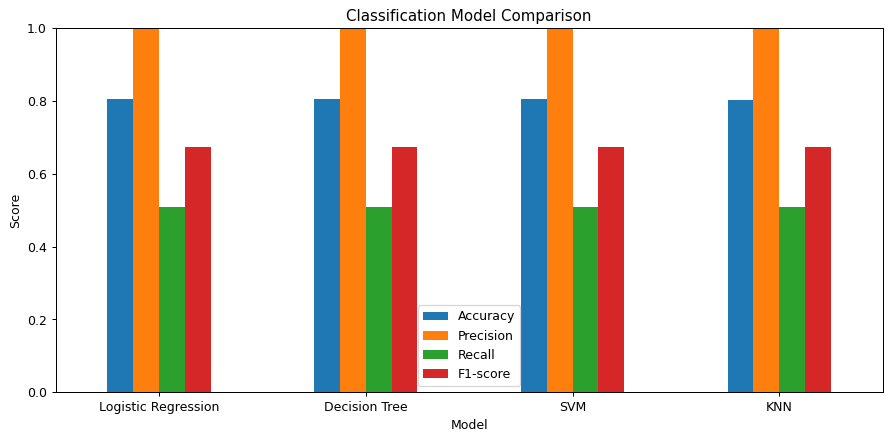

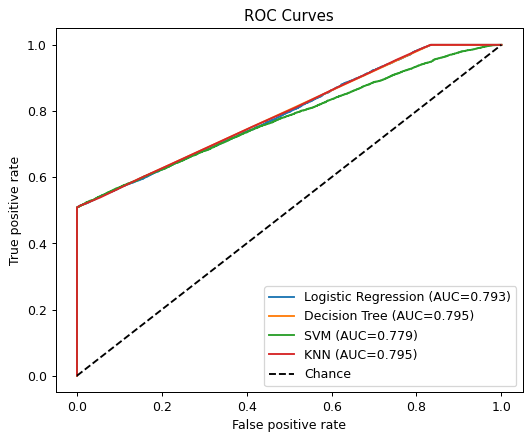

In [14]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "SVM": svm_model,
    "KNN": knn_model
}
rows = []
for name, model in models.items():
    predictions = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })
comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(4))
comparison[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", ylim=(0, 1), figsize=(10, 5), title="Classification Model Comparison")
plt.ylabel("Score"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# ROC curves for all four classifiers
plt.figure(figsize=(6, 5))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={comparison.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC Curves"); plt.legend(); plt.tight_layout(); plt.show()

# Overall summary of all five models
print("Regression (Multiple Linear Regression) - daily energy:")
print("  R-squared:", round(r2_score(y_test_reg, pred_reg), 4),
      "| RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, pred_reg)), 2), "kWh")

## 12. Conclusion

This notebook applies regression and classification to smart-home energy data. Regression is evaluated with MAE, MSE, RMSE, and R-squared. Classification (Logistic Regression, Decision Tree, SVM, and KNN) is evaluated with accuracy, precision, recall, F1-score, confusion matrix, ROC-AUC, and log loss where applicable. KNN replaces K-Means from the reference notebook and is compared directly with the other three classifiers.

**For your report/viva:** clearly state that "High Consumption" means a reading above the dataset's mean energy use, and that train/test sets are split by time (first 80% / last 20%). Results depend on the dataset and this definition. Daily totals are essentially random in this dataset, so the regression model has little predictive power, whereas appliance type strongly determines whether a reading is high, so all four classifiers reach similar accuracy.